## Phase 2: Static Word Embeddings

### Research Question
How can a computer represent the meaning/relationships of words as vectors?

### Objectives
- Understand vectors and semantic space
- Use pretrained embeddings
- Visualize word relationships
- Understand Word2Vec: including how it learns embeddings

In [2]:
import gensim.downloader as api

# This downloads a pre-trained model. It has been trained from a large numebr of text.
#  The 50 means that each word is represented by 50 words in a matrix
model = api.load("glove-wiki-gigaword-50") 

vector = model['cat']

print(vector)
print(vector.shape)

[ 0.45281  -0.50108  -0.53714  -0.015697  0.22191   0.54602  -0.67301
 -0.6891    0.63493  -0.19726   0.33685   0.7735    0.90094   0.38488
  0.38367   0.2657   -0.08057   0.61089  -1.2894   -0.22313  -0.61578
  0.21697   0.35614   0.44499   0.60885  -1.1633   -1.1579    0.36118
  0.10466  -0.78325   1.4352    0.18629  -0.26112   0.83275  -0.23123
  0.32481   0.14485  -0.44552   0.33497  -0.95946  -0.097479  0.48138
 -0.43352   0.69455   0.91043  -0.28173   0.41637  -1.2609    0.71278
  0.23782 ]
(50,)


In [3]:
#model.most_similar('cat')
model.most_similar('bank')

[('banks', 0.869862973690033),
 ('securities', 0.7996813654899597),
 ('banking', 0.7965160012245178),
 ('investment', 0.7849708199501038),
 ('exchange', 0.7808825969696045),
 ('financial', 0.7670274972915649),
 ('credit', 0.764915406703949),
 ('lender', 0.7518407702445984),
 ('capital', 0.7380707859992981),
 ('brokerage', 0.7373986840248108)]

In [4]:
# The relationship between the words
model.similarity('bank', 'river')

np.float32(0.4142035)

In [5]:
model["bank"]

array([ 0.66488 , -0.11391 ,  0.67844 ,  0.17951 ,  0.6828  , -0.47787 ,
       -0.30761 ,  0.17489 , -0.70512 , -0.55022 ,  0.1514  ,  0.10214 ,
       -0.45063 , -0.33069 ,  0.056133,  1.2271  ,  0.55607 , -0.68297 ,
        0.037364,  0.70266 ,  1.9093  , -0.61483 , -0.83329 , -0.3023  ,
       -1.1118  , -1.55    ,  0.2604  ,  0.22957 , -1.0375  , -0.31789 ,
        3.5091  , -0.25871 ,  1.0151  ,  0.65927 , -0.18231 , -0.75859 ,
       -0.30927 , -0.91678 ,  1.0633  , -0.66761 , -0.37464 , -0.29143 ,
        0.65606 , -0.44642 , -0.075495, -1.0552  , -0.60501 ,  0.73582 ,
        1.0139  , -0.27749 ], dtype=float32)

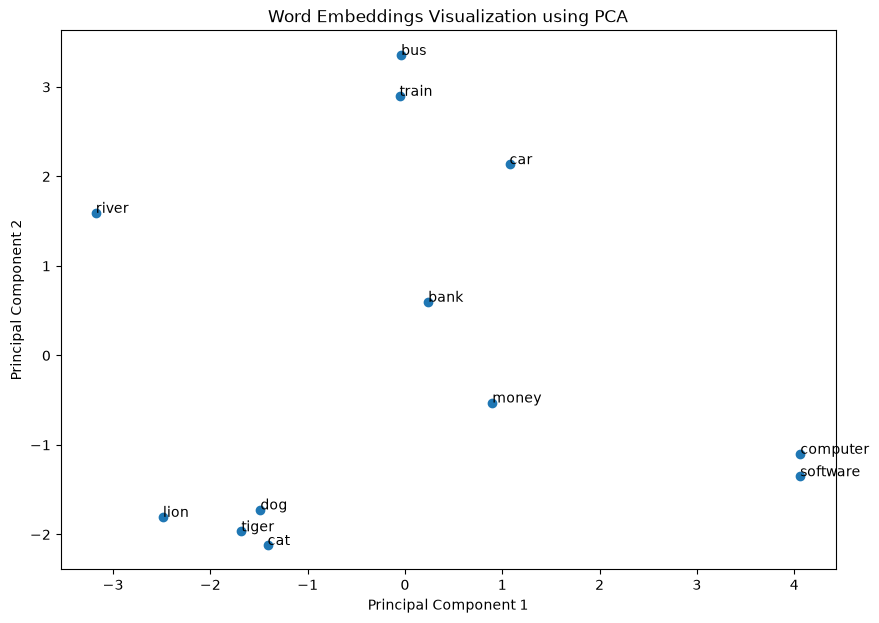

In [6]:
#Visualizing the word embeddings using PCA
words = [
    "cat",
    "dog",
    "lion",
    "tiger",
    "car",
    "bus",
    "train",
    "computer",
    "software",
    "bank",
    "money",
    "river"
]

vectors = [model[word] for word in words]


from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
pca = PCA(n_components=2)
vectors_2d = pca.fit_transform(vectors)

#Plotting the 2D representation of the word embeddings
plt.figure(figsize=(10, 7))
plt.scatter(vectors_2d[:, 0], vectors_2d[:, 1])

for i, word in enumerate(words):
    plt.annotate(word, (vectors_2d[i, 0], vectors_2d[i, 1]))

plt.title("Word Embeddings Visualization using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.show()

In [7]:
sentence_a = "The bank approved my loan."
sentence_b = "The fisherman sat on the bank of the river."

bank_a = model["bank"]
bank_b = model["bank"]

print("Sentence A vector shape:", bank_a.shape)
print("Sentence B vector shape:", bank_b.shape)

print("Are the vectors identical?",
      (bank_a == bank_b).all())

Sentence A vector shape: (50,)
Sentence B vector shape: (50,)
Are the vectors identical? True


With GloVe we can see that a word has the exact same vector regardless of the sentence meaning because the model refers to the same vector for both sentences.